## Name : Krish Potanwar
## Class : C2
## Batch : B2
## Roll no. : 21

## ML Lab 9

In [5]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, calinski_harabasz_score, davies_bouldin_score, calinski_harabasz_score)

from scipy.cluster.hierarchy import linkage, dendrogram

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

In [6]:
df = pd.read_csv("Wholesale customers data.csv")

In [7]:
df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [8]:
df.tail()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
435,1,3,29703,12051,16027,13135,182,2204
436,1,3,39228,1431,764,4510,93,2346
437,2,3,14531,15488,30243,437,14841,1867
438,1,3,10290,1981,2232,1038,168,2125
439,1,3,2787,1698,2510,65,477,52


In [9]:
df.shape

(440, 8)

In [10]:
df.dtypes

,0
Channel,int64
Region,int64
Fresh,int64
Milk,int64
Grocery,int64
Frozen,int64
Detergents_Paper,int64
Delicassen,int64


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB


In [12]:
df.describe()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000
mean,1.322727,2.543182,12000.297727,5796.265909,7951.277273,3071.931818,2881.493182,1524.870455
std,0.468052,0.774272,12647.328865,7380.377175,9503.162829,4854.673333,4767.854448,2820.105937
min,1.000000,1.000000,3.000000,55.000000,3.000000,25.000000,3.000000,3.000000
25%,1.000000,2.000000,3127.750000,1533.000000,2153.000000,742.250000,256.750000,408.250000
50%,1.000000,3.000000,8504.000000,3627.000000,4755.500000,1526.000000,816.500000,965.500000
75%,2.000000,3.000000,16933.750000,7190.250000,10655.750000,3554.250000,3922.000000,1820.250000
max,2.000000,3.000000,112151.000000,73498.000000,92780.000000,60869.000000,40827.000000,47943.000000


In [13]:
df.isnull().sum()

,0
Channel,0
Region,0
Fresh,0
Milk,0
Grocery,0
Frozen,0
Detergents_Paper,0
Delicassen,0


In [14]:
df.duplicated().sum()

np.int64(0)

In [15]:
features = [
    "Frozen",
    "Milk",
    "Grocery",
    "Fresh",
    "Detergents_Paper",
    "Delicassen"
]

X = df[features].copy()

display(X.head())
print("Numbers pd records used Clustering", len(X))

,Frozen,Milk,Grocery,Fresh,Detergents_Paper,Delicassen
0,214,9656,7561,12669,2674,1338
1,1762,9810,9568,7057,3293,1776
2,2405,8808,7684,6353,3516,7844
3,6404,1196,4221,13265,507,1788
4,3915,5410,7198,22615,1777,5185


Numbers pd records used Clustering 440


In [16]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [17]:
X_scaled_df = pd.DataFrame(X_scaled, columns=features, index = X.index)

In [18]:
print("First five scaled records")
display(X_scaled_df.head())

First five scaled records


,Frozen,Milk,Grocery,Fresh,Detergents_Paper,Delicassen
0,-0.589367,0.523568,-0.041115,0.052933,-0.043569,-0.066339
1,-0.270136,0.544458,0.170318,-0.391302,0.086407,0.089151
2,-0.137536,0.408538,-0.028157,-0.447029,0.133232,2.243293
3,0.687144,-0.624020,-0.392977,0.100111,-0.498588,0.093411
4,0.173859,-0.052396,-0.079356,0.840239,-0.231918,1.299347


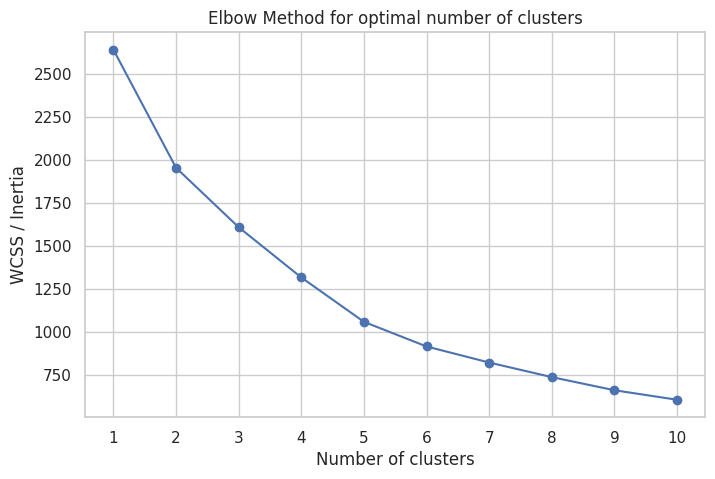

In [19]:
wcss = []
k_values = range(1, 11)
for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42,n_init=42)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8,5))
plt.plot(list(k_values), wcss, marker="o")
plt.title("Elbow Method for optimal number of clusters")
plt.xlabel("Number of clusters")
plt.ylabel("WCSS / Inertia")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

In [20]:
silhouette_values = []

for k in range(2,11):
  model = KMeans(n_clusters = k , random_state=42, n_init =10)
  labels = model.fit_predict(X_scaled)
  score = silhouette_score(X_scaled, labels)
  silhouette_values.append(score)

silhouette_table = pd.DataFrame({
    "Number of clusters" : list(range(2,11)),
    "Silhouette score" : silhouette_values
})

display(silhouette_table.round(4))

,Number of clusters,Silhouette score
0,2,0.5472
1,3,0.5483
2,4,0.3485
3,5,0.3690
4,6,0.3782
5,7,0.3343
6,8,0.3201
7,9,0.3090
8,10,0.3112


In [21]:
suggested_k = int(
    silhouette_table.loc[silhouette_table["Silhouette score"].idxmax(), "Number of clusters"]
)

print("K suggested by the highest silhouette score : ", suggested_k)

K suggested by the highest silhouette score :  3


In [22]:
K = suggested_k

kmeans_model = KMeans(n_clusters = K, random_state=42, n_init =10)
kmeans_labels = kmeans_model.fit_predict(X_scaled)

In [23]:
df_kmeans = df.copy()
df_kmeans["KMeans_Cluster"] = kmeans_labels

print("K-means clustering completed")
print("\nNumber of customers in each cluster :")
print(df_kmeans["KMeans_Cluster"].value_counts().sort_index())

print("\nSample recods with cluster labels :")
display(df_kmeans.head())

K-means clustering completed

Number of customers in each cluster :
KMeans_Cluster
0     45
1    393
2      2
Name: count, dtype: int64

Sample recods with cluster labels :


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,KMeans_Cluster
0,2,3,12669,9656,7561,214,2674,1338,1
1,2,3,7057,9810,9568,1762,3293,1776,1
2,2,3,6353,8808,7684,2405,3516,7844,1
3,1,3,13265,1196,4221,6404,507,1788,1
4,2,3,22615,5410,7198,3915,1777,5185,1


In [24]:
hierarchical_model = AgglomerativeClustering(n_clusters=K, linkage="ward", metric="euclidean")
hierarchical_labels = hierarchical_model.fit_predict(X_scaled)

In [25]:
# Store the Cluster Labels
df_hierarchical = df.copy()
df_hierarchical["Hierarchical_Cluster"] = hierarchical_labels

print("Hierarchical clustering completed")
print("\nNumber of customers in each cluster :")
print(df_hierarchical["Hierarchical_Cluster"].value_counts().sort_index())

print("\nSample recods with cluster labels :")
display(df_hierarchical.head())

Hierarchical clustering completed

Number of customers in each cluster :
Hierarchical_Cluster
0      6
1    281
2    153
Name: count, dtype: int64

Sample recods with cluster labels :


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Hierarchical_Cluster
0,2,3,12669,9656,7561,214,2674,1338,2
1,2,3,7057,9810,9568,1762,3293,1776,2
2,2,3,6353,8808,7684,2405,3516,7844,2
3,1,3,13265,1196,4221,6404,507,1788,1
4,2,3,22615,5410,7198,3915,1777,5185,1


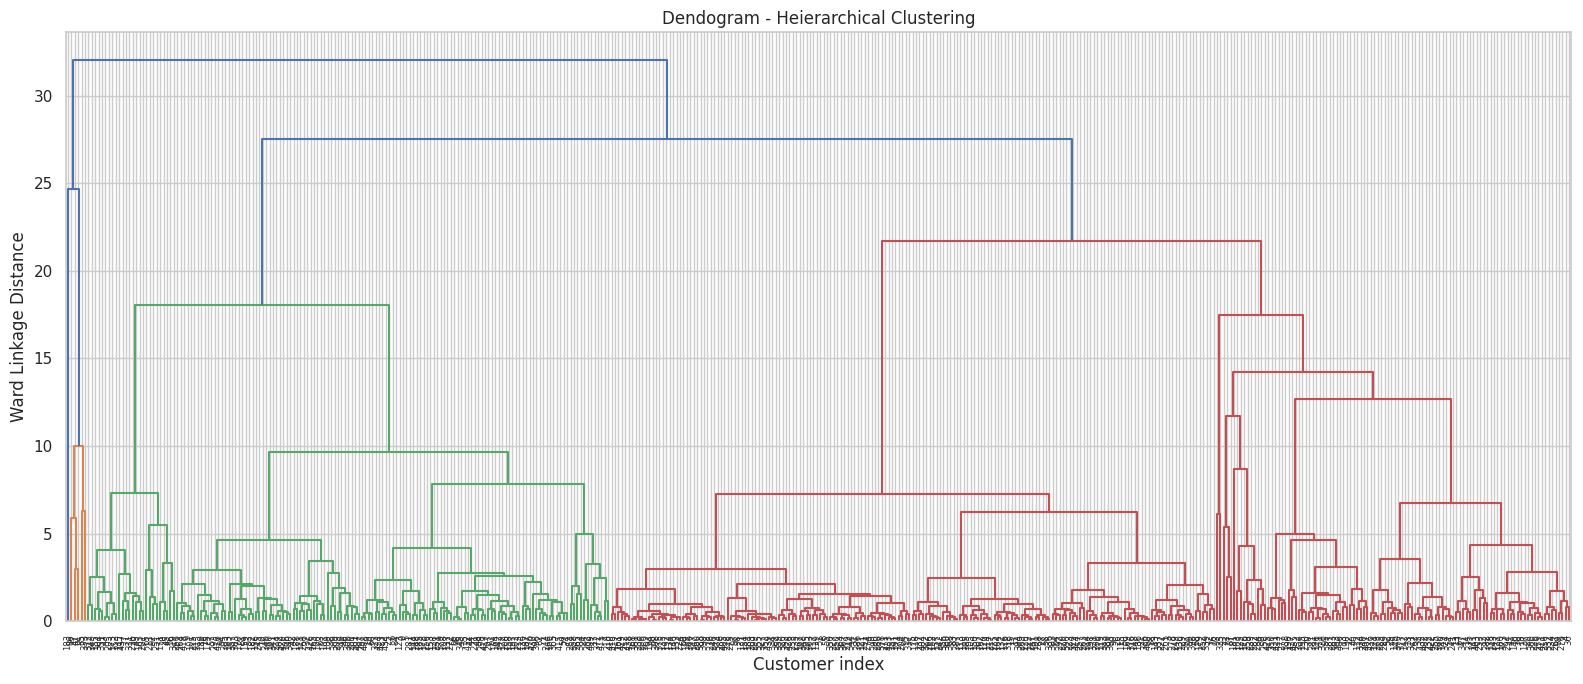

In [26]:
Z = linkage(X_scaled, method="ward", metric="euclidean")


plt.figure(figsize=(16, 7))
dendrogram(Z, leaf_rotation=90,leaf_font_size=6)

plt.title("Dendogram - Heierarchical Clustering")
plt.xlabel("Customer index")
plt.ylabel("Ward Linkage Distance")
plt.tight_layout()
plt.show()

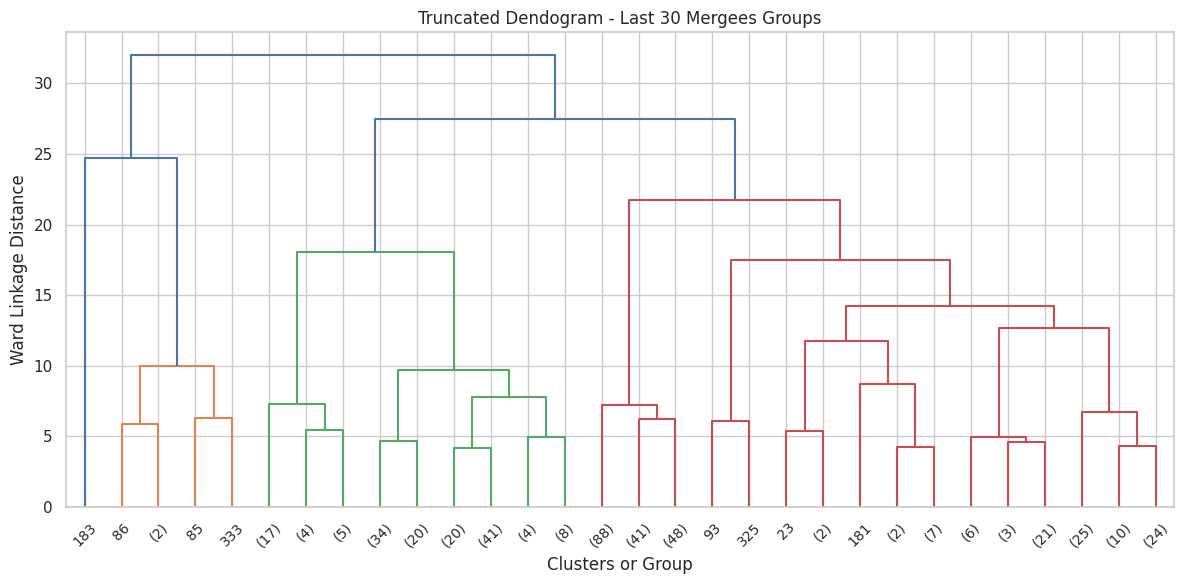

In [27]:
# Trunate dendogram for easier interpretation
plt.figure(figsize=(12,6))
dendrogram(Z, truncate_mode="lastp", p=30, show_leaf_counts=True,leaf_rotation=45)

plt.title("Truncated Dendogram - Last 30 Mergees Groups")
plt.xlabel("Clusters or Group")
plt.ylabel("Ward Linkage Distance")
plt.tight_layout()
plt.show()

In [28]:
# REduce six scaled features to two pricipal components
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("Variance explained by the two components:",round(pca.explained_variance_ratio_.sum()*100,2),"%")

plot_df = pd.DataFrame({"PC1": X_pca[:, 0], "PC2": X_pca[:, 1], "KMeans_Cluster": kmeans_labels.astype(str),"Hierarchical_Cluster": hierarchical_labels.astype(str)})
display(plot_df.head())

Variance explained by the two components: 72.46 %


,PC1,PC2,KMeans_Cluster,Hierarchical_Cluster
0,0.193291,-0.305100,1,2
1,0.434420,-0.328413,1,2
2,0.811143,0.815096,1,2
3,-0.778648,0.652754,1,1
4,0.166287,1.271434,1,1


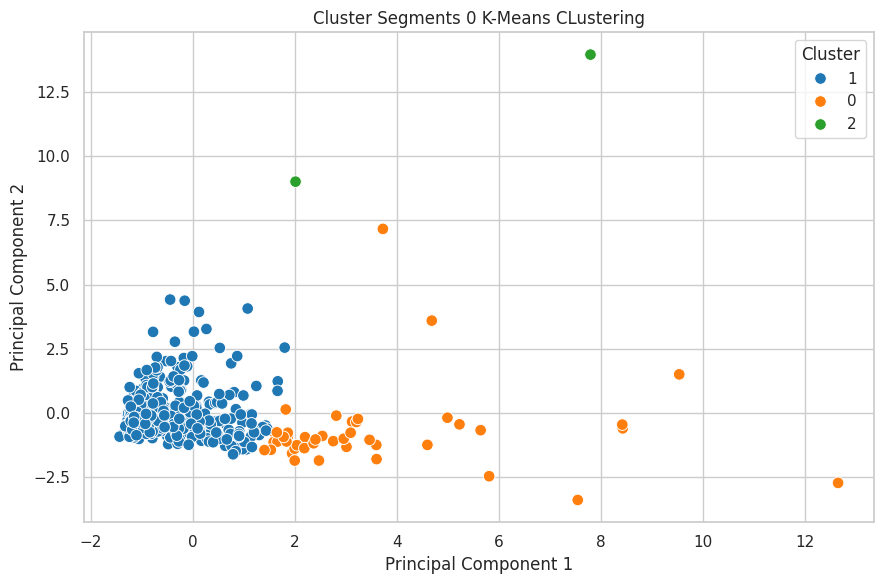

In [29]:
# Kmean visualization
plt.figure(figsize=(9, 6))
sns.scatterplot(data=plot_df,x="PC1",y="PC2",hue="KMeans_Cluster",palette="tab10",s=70)
plt.title("Cluster Segments 0 K-Means CLustering")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

In [30]:
# Function
def evaluate_cluster(X_data, labels, model_name):
  return{
      "Algorithm": model_name,
      "Number of Clusters": len(np.unique(labels)),
      "Silhouette Score": silhouette_score(X_data, labels),
      "Calinski Harabasz Score": calinski_harabasz_score(X_data, labels),
      "Davies Bouldin Score": davies_bouldin_score(X_data, labels)
  }

In [31]:
cluster_sizes = pd.DataFrame({
    "K-Means": pd.Series(kmeans_labels).value_counts().sort_index(),
    "Hierarchical": pd.Series(hierarchical_labels).value_counts().sort_index()
}).fillna(0).astype(int)

print("Cluster sizes")
display(cluster_sizes)

Cluster sizes


,K-Means,Hierarchical
0,45,6
1,393,281
2,2,153


In [33]:
kmeans_profile = df[features].copy()
kmeans_profile["Cluster"] = kmeans_labels

kmeans_means = kmeans_profile.groupby("Cluster")[features].mean()
print("Average Spending by K-Means Clusters:")
display(kmeans_means)

Average Spending by K-Means Clusters:


,Frozen,Milk,Grocery,Fresh,Detergents_Paper,Delicassen
Cluster,,,,,,
0,2190.244444,19386.422222,28656.088889,10440.933333,13327.800000,2374.200000
1,2940.676845,4115.099237,5534.966921,12062.913486,1696.170483,1299.114504
2,48701.500000,30367.000000,16898.000000,34782.000000,755.500000,26776.000000


In [34]:
cluster_distribution = pd.DataFrame({
    "Customer Count": pd.Series(kmeans_labels).value_counts().sort_index()
})

cluster_distribution["Percentage"] = (
    cluster_distribution["Customer Count"]/ len(df)*100).round(2)

print("K mean customer distribution")
display(cluster_distribution)

K mean customer distribution


,Customer Count,Percentage
0,45,10.23
1,393,89.32
2,2,0.45


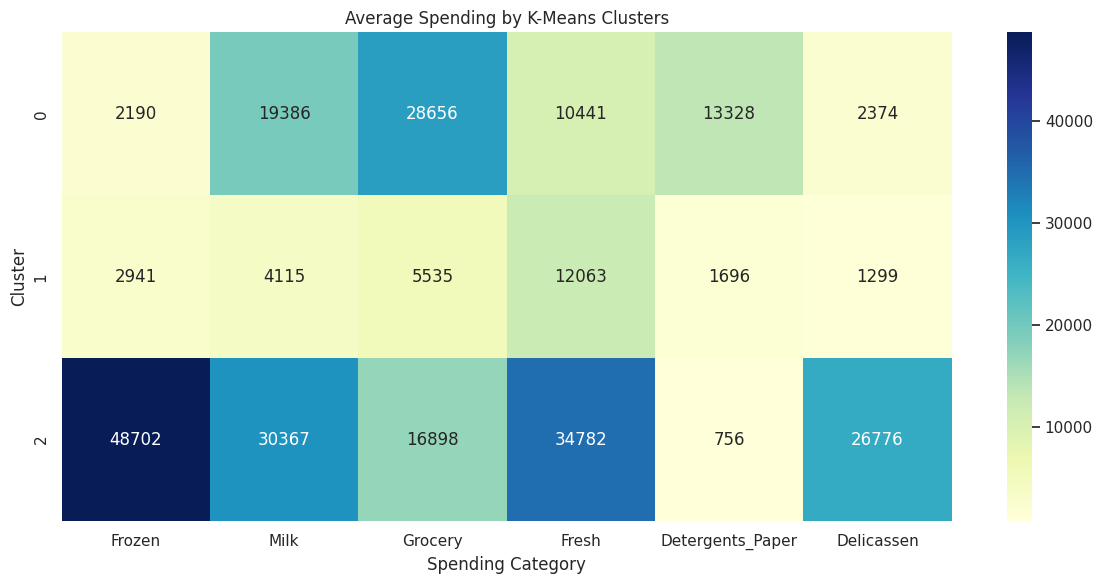

In [35]:
plt.figure(figsize=(12, 6))
sns.heatmap(kmeans_means,annot=True,fmt=".0f",cmap="YlGnBu")
plt.title("Average Spending by K-Means Clusters")
plt.xlabel("Spending Category")
plt.ylabel("Cluster")
plt.tight_layout()
plt.show()

In [36]:
channel_mix = pd.crosstab(df["Channel"],kmeans_labels, normalize="columns")*100
channel_mix.columns = [f"cluster {c}"for c in channel_mix.columns]
print("Channel composition within each K - means cluster (%):")
display(channel_mix.round(2))

Channel composition within each K - means cluster (%):


,cluster 0,cluster 1,cluster 2
Channel,,,
1,2.22,75.06,100.0
2,97.78,24.94,0.0
